# 08 — Cross-terrain threshold generalization

Does a global threshold tuned on one terrain still work on another?
We fit Otsu / Kittler / GMM on farmland vs urban, then transfer each
threshold to the other terrain and measure the F1 drop.


In [1]:
# Setup — run this cell first.
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "code" / "config" / "config.yaml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "code" / "preprocessing"))
print("project root:", ROOT)
"""Cross-terrain threshold generalization test.

A global threshold is estimated from the histogram of ONE terrain, then applied
to a DIFFERENT terrain, and the resulting flood map is scored against Sentinel-2
water. The gap between "in-place" (threshold fit on the test terrain) and
"transferred" (threshold fit on another terrain) F1 measures how scene-specific
each thresholding method is.

Terrains (ESA WorldCover): farmland = class 40 (cropland), urban = class 50.

Outputs: outputs/tables/cross_terrain.csv, outputs/figures/cross_terrain.png
"""

from __future__ import annotations

import csv
import sys
from pathlib import Path


import matplotlib

import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib.colors import ListedColormap
import numpy as np
import rasterio
from skimage.filters import threshold_otsu

from common import load_config, rel_path

DB_NODATA = -9999.0


def read(path):
    with rasterio.open(path) as src:
        return src.read(1)


def kittler_threshold(x, bins=256):
    x = np.asarray(x, dtype=np.float64)
    x = x[np.isfinite(x)]
    lo, hi = float(x.min()), float(x.max())
    if hi <= lo:
        return float("nan")
    hist, edges = np.histogram(x, bins=bins, range=(lo, hi))
    centers = (edges[:-1] + edges[1:]) / 2.0
    total = float(hist.sum())
    best_t, best_j = None, np.inf
    for i in range(1, len(centers)):
        h1, h2 = hist[:i], hist[i:]
        c1, c2 = centers[:i], centers[i:]
        n1, n2 = float(h1.sum()), float(h2.sum())
        if n1 == 0 or n2 == 0:
            continue
        p1, p2 = n1 / total, n2 / total
        m1 = float((h1 * c1).sum() / n1)
        m2 = float((h2 * c2).sum() / n2)
        v1 = float((h1 * (c1 - m1) ** 2).sum() / n1)
        v2 = float((h2 * (c2 - m2) ** 2).sum() / n2)
        if v1 <= 0 or v2 <= 0:
            continue
        s1, s2 = np.sqrt(v1), np.sqrt(v2)
        j = 1.0 + 2.0 * (p1 * np.log(s1) + p2 * np.log(s2)) - 2.0 * (p1 * np.log(p1) + p2 * np.log(p2))
        if j < best_j:
            best_j, best_t = j, float(centers[i])
    return best_t


def gmm_threshold(x, n_iter=40, n_grid=20001):
    x = np.asarray(x, dtype=np.float64)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return float("nan")
    mu1 = float(np.percentile(x, 35))
    mu2 = float(np.percentile(x, 65))
    s1 = s2 = float(np.std(x))
    w1 = w2 = 0.5
    for _ in range(n_iter):
        p1 = np.exp(-0.5 * ((x - mu1) / s1) ** 2) / (s1 * np.sqrt(2 * np.pi))
        p2 = np.exp(-0.5 * ((x - mu2) / s2) ** 2) / (s2 * np.sqrt(2 * np.pi))
        r = w1 * p1 / (w1 * p1 + w2 * p2 + 1e-300)
        n1 = r.sum()
        n2 = x.size - n1
        w1 = float(n1 / x.size)
        w2 = 1.0 - w1
        mu1 = float((r * x).sum() / n1)
        mu2 = float(((1.0 - r) * x).sum() / n2)
        s1 = max(float(np.sqrt((r * (x - mu1) ** 2).sum() / n1)), 1e-6)
        s2 = max(float(np.sqrt(((1.0 - r) * (x - mu2) ** 2).sum() / n2)), 1e-6)
    if mu1 > mu2:
        mu1, mu2 = mu2, mu1
        s1, s2 = s2, s1
        w1, w2 = w2, w1
    xs = np.linspace(mu1, mu2, n_grid)
    lp1 = np.log(w1) - np.log(s1) - 0.5 * ((xs - mu1) / s1) ** 2
    lp2 = np.log(w2) - np.log(s2) - 0.5 * ((xs - mu2) / s2) ** 2
    d = lp1 - lp2
    cross = np.where(np.diff(np.sign(d)) != 0)[0]
    return float(xs[cross[0]]) if cross.size else float((mu1 + mu2) / 2.0)


def score(mask, s2_water, evaluable):
    tp = int((mask & s2_water & evaluable).sum())
    fp = int((mask & ~s2_water & evaluable).sum())
    fn = int((~mask & s2_water & evaluable).sum())
    prec = tp / (tp + fp) if (tp + fp) else float("nan")
    rec = tp / (tp + fn) if (tp + fn) else float("nan")
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else float("nan")
    return {"precision": round(prec, 4), "recall": round(rec, 4), "f1": round(f1, 4)}


THRESHOLDERS = {"otsu": lambda x: float(threshold_otsu(x)),
                "kittler": kittler_threshold,
                "gmm": gmm_threshold}


project root: D:\DIVP PROJECT


## Step 1 — Load data, domain, and the Sentinel-2 reference

In [2]:
cfg = load_config()
processed = rel_path(cfg, "data_processed")
tables = rel_path(cfg, "outputs") / "tables"
figures = rel_path(cfg, "outputs") / "figures"
tables.mkdir(parents=True, exist_ok=True)
figures.mkdir(parents=True, exist_ok=True)

post_vv = read(processed / "s1_post_vv_db.tif")
slope = read(processed / "slope_deg.tif")
permanent = read(processed / "masks" / "permanent_water.tif")
lc = read(rel_path(cfg, "data_raw") / "landcover" / "worldcover_aoi.tif")

valid = (post_vv != DB_NODATA) & (slope != DB_NODATA)
base = valid & (permanent == 0)
slope_ok = slope <= cfg["masks"]["slope_deg_max"]
domain = base & slope_ok

s2p = rel_path(cfg, "data_raw") / "sentinel2"
b03 = read(s2p / "s2_post_B03.tif").astype("float32")
b11 = read(s2p / "s2_post_B11.tif").astype("float32")
scl = read(s2p / "s2_post_SCL.tif")
clear = np.isin(scl, [2, 4, 5, 6, 7]) & (b03 > 0) & (b11 > 0)
denom = b03 + b11
mndwi = np.full(b03.shape, np.nan, dtype="float32")
ok = clear & (denom > 0)
mndwi[ok] = (b03[ok] - b11[ok]) / denom[ok]
s2_water = np.isfinite(mndwi) & (mndwi > cfg["validation"]["mndwi"]["threshold"]) & domain
evaluable = clear & domain


## Step 2 — Terrain masks (farmland vs urban)

In [3]:
# ---- terrain masks ----
terrains = {"farm": lc == 40, "urban": lc == 50}


## Step 3 — Fit thresholds on one terrain, apply to the other

In [4]:
# ---- threshold transfer ----
rows = []
for name, thresh_fn in THRESHOLDERS.items():
    thresh_farm = thresh_fn(post_vv[domain & terrains["farm"]].astype("float64"))
    thresh_urban = thresh_fn(post_vv[domain & terrains["urban"]].astype("float64"))

    # transfer farm -> urban
    tr_mask = (post_vv < thresh_farm) & domain & terrains["urban"]
    ip_mask = (post_vv < thresh_urban) & domain & terrains["urban"]
    tr = score(tr_mask, s2_water, evaluable & terrains["urban"])
    ip = score(ip_mask, s2_water, evaluable & terrains["urban"])
    rows.append({
        "method": name, "transfer": "farm->urban",
        "thresh_farm": f"{thresh_farm:.3f}", "thresh_urban": f"{thresh_urban:.3f}",
        "transferred_f1": tr["f1"], "transferred_precision": tr["precision"],
        "inplace_f1": ip["f1"], "inplace_precision": ip["precision"],
        "f1_gap": round(ip["f1"] - tr["f1"], 4),
    })

    # transfer urban -> farm
    tr_mask = (post_vv < thresh_urban) & domain & terrains["farm"]
    ip_mask = (post_vv < thresh_farm) & domain & terrains["farm"]
    tr = score(tr_mask, s2_water, evaluable & terrains["farm"])
    ip = score(ip_mask, s2_water, evaluable & terrains["farm"])
    rows.append({
        "method": name, "transfer": "urban->farm",
        "thresh_farm": f"{thresh_farm:.3f}", "thresh_urban": f"{thresh_urban:.3f}",
        "transferred_f1": tr["f1"], "transferred_precision": tr["precision"],
        "inplace_f1": ip["f1"], "inplace_precision": ip["precision"],
        "f1_gap": round(ip["f1"] - tr["f1"], 4),
    })

with open(tables / "cross_terrain.csv", "w", newline="", encoding="utf-8") as h:
    w = csv.DictWriter(h, fieldnames=list(rows[0].keys()))
    w.writeheader()
    w.writerows(rows)


## Step 4 — Cross-terrain figure

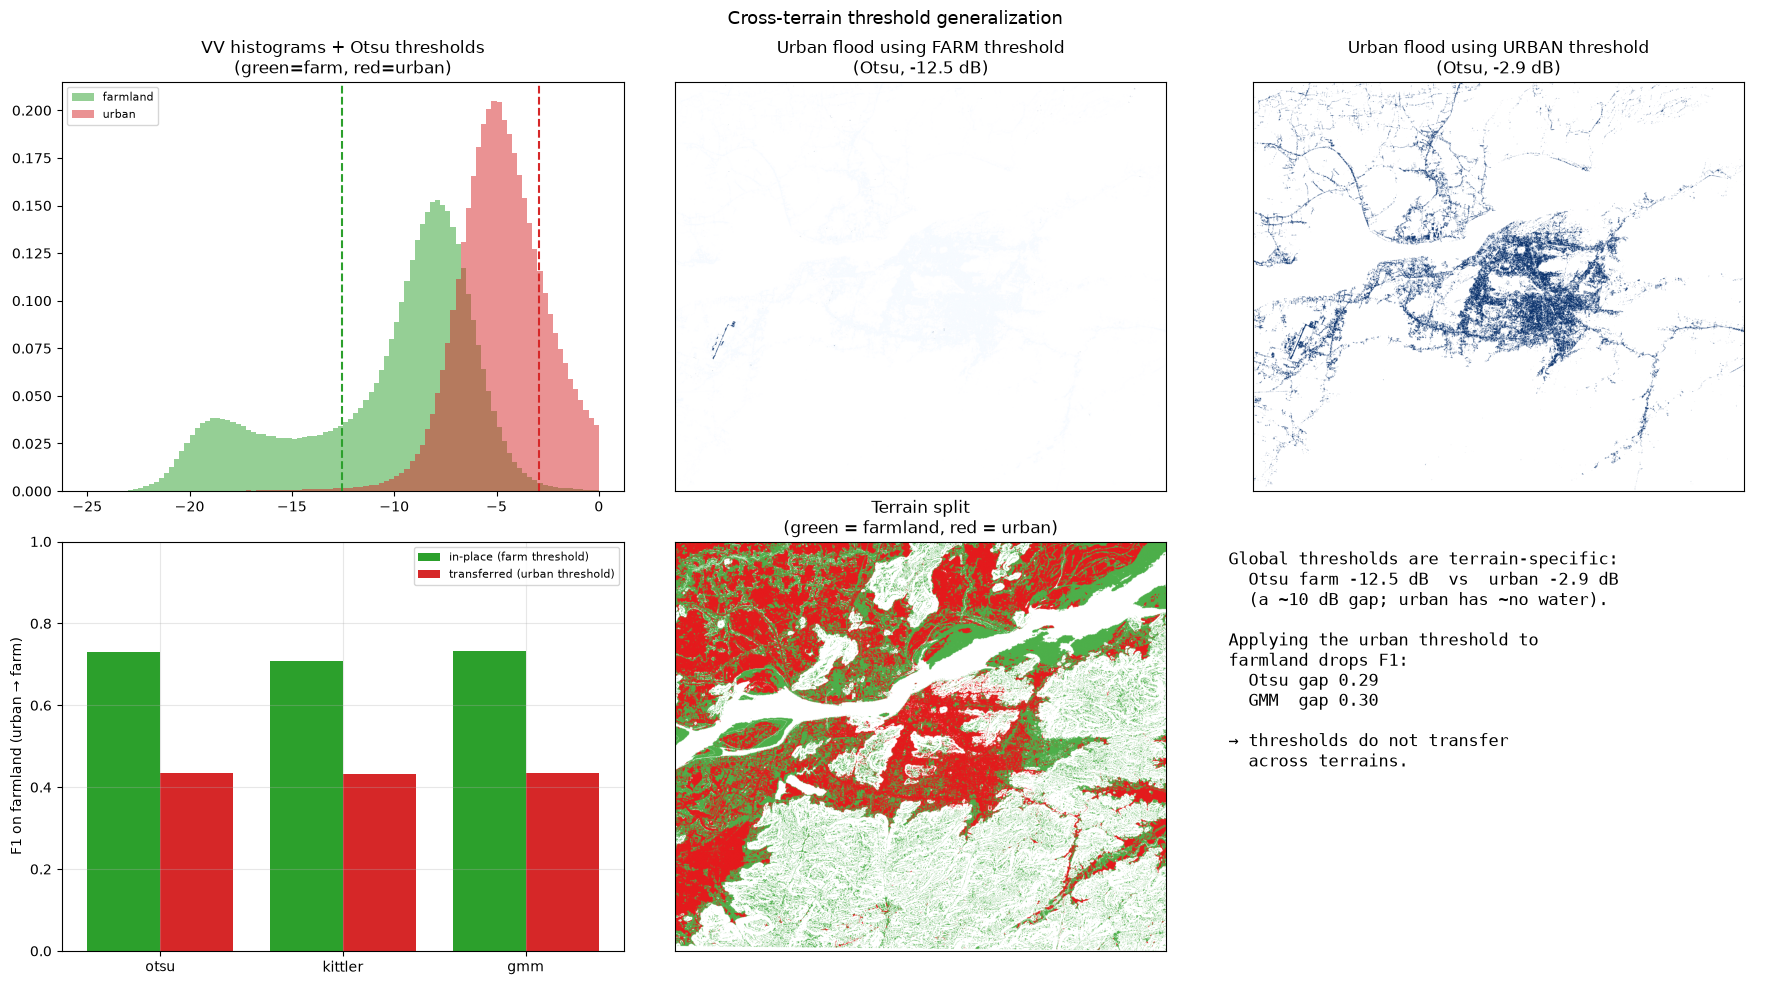

=== cross-terrain ===
   {'method': 'otsu', 'transfer': 'farm->urban', 'thresh_farm': '-12.538', 'thresh_urban': '-2.910', 'transferred_f1': 0.0575, 'transferred_precision': 0.0413, 'inplace_f1': 0.0032, 'inplace_precision': 0.0016, 'f1_gap': -0.0543}
   {'method': 'otsu', 'transfer': 'urban->farm', 'thresh_farm': '-12.538', 'thresh_urban': '-2.910', 'transferred_f1': 0.4349, 'transferred_precision': 0.278, 'inplace_f1': 0.7296, 'inplace_precision': 0.7963, 'f1_gap': 0.2947}
   {'method': 'kittler', 'transfer': 'farm->urban', 'thresh_farm': '-13.634', 'thresh_urban': '2.598', 'transferred_f1': 0.057, 'transferred_precision': 0.0489, 'inplace_f1': 0.0033, 'inplace_precision': 0.0017, 'f1_gap': -0.0537}
   {'method': 'kittler', 'transfer': 'urban->farm', 'thresh_farm': '-13.634', 'thresh_urban': '2.598', 'transferred_f1': 0.4334, 'transferred_precision': 0.2767, 'inplace_f1': 0.7086, 'inplace_precision': 0.833, 'f1_gap': 0.2752}
   {'method': 'gmm', 'transfer': 'farm->urban', 'thresh_far

In [5]:
# ---- figure ----
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
# histograms + thresholds
farm_vals = post_vv[domain & terrains["farm"]]
urban_vals = post_vv[domain & terrains["urban"]]
axes[0, 0].hist(farm_vals, bins=100, range=(-25, 0), alpha=0.5, color="tab:green", density=True, label="farmland")
axes[0, 0].hist(urban_vals, bins=100, range=(-25, 0), alpha=0.5, color="tab:red", density=True, label="urban")
axes[0, 0].axvline(THRESHOLDERS["otsu"](farm_vals.astype("float64")), color="tab:green", ls="--")
axes[0, 0].axvline(THRESHOLDERS["otsu"](urban_vals.astype("float64")), color="tab:red", ls="--")
axes[0, 0].set_title("VV histograms + Otsu thresholds\n(green=farm, red=urban)")
axes[0, 0].legend(fontsize=8)

# transferred vs in-place urban masks (otsu)
t_farm = THRESHOLDERS["otsu"](farm_vals.astype("float64"))
t_urb = THRESHOLDERS["otsu"](urban_vals.astype("float64"))
axes[0, 1].imshow(np.where(domain & terrains["urban"], post_vv < t_farm, np.nan), cmap="Blues", vmin=0, vmax=1)
axes[0, 1].set_title(f"Urban flood using FARM threshold\n(Otsu, {t_farm:.1f} dB)")
axes[0, 2].imshow(np.where(domain & terrains["urban"], post_vv < t_urb, np.nan), cmap="Blues", vmin=0, vmax=1)
axes[0, 2].set_title(f"Urban flood using URBAN threshold\n(Otsu, {t_urb:.1f} dB)")

# F1 bar chart: in-place vs transferred, per method (urban -> farm)
methods = [r["method"] for r in rows if r["transfer"] == "urban->farm"]
inplace = [r["inplace_f1"] for r in rows if r["transfer"] == "urban->farm"]
transfer = [r["transferred_f1"] for r in rows if r["transfer"] == "urban->farm"]
x = np.arange(len(methods))
axes[1, 0].bar(x - 0.2, inplace, 0.4, label="in-place (farm threshold)", color="tab:green")
axes[1, 0].bar(x + 0.2, transfer, 0.4, label="transferred (urban threshold)", color="tab:red")
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(methods)
axes[1, 0].set_ylabel("F1 on farmland (urban → farm)")
axes[1, 0].set_ylim(0, 1)
axes[1, 0].legend(fontsize=8)
axes[1, 0].grid(alpha=0.3)

# terrain map
terr = np.where(terrains["farm"], 1, 0).astype("int8")
terr[terrains["urban"]] = 2
terr = np.where(domain, terr, np.nan)
axes[1, 1].imshow(terr, cmap=ListedColormap(["#4daf4a", "#e41a1c"]), vmin=0, vmax=2)
axes[1, 1].set_title("Terrain split\n(green = farmland, red = urban)")

axes[1, 2].axis("off")
gap_otsu = next(r["f1_gap"] for r in rows if r["method"] == "otsu" and r["transfer"] == "urban->farm")
gap_gmm = next(r["f1_gap"] for r in rows if r["method"] == "gmm" and r["transfer"] == "urban->farm")
t_farm_o = next(float(r["thresh_farm"]) for r in rows if r["method"] == "otsu")
t_urb_o = next(float(r["thresh_urban"]) for r in rows if r["method"] == "otsu")
axes[1, 2].text(0.02, 0.98,
                "Global thresholds are terrain-specific:\n"
                f"  Otsu farm {t_farm_o:.1f} dB  vs  urban {t_urb_o:.1f} dB\n"
                "  (a ~10 dB gap; urban has ~no water).\n\n"
                "Applying the urban threshold to\n"
                "farmland drops F1:\n"
                f"  Otsu gap {gap_otsu:.2f}\n"
                f"  GMM  gap {gap_gmm:.2f}\n\n"
                "→ thresholds do not transfer\n"
                "  across terrains.",
                va="top", ha="left", fontsize=12, family="monospace")

for ax in (axes[0, 1], axes[0, 2], axes[1, 1]):
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Cross-terrain threshold generalization", fontsize=13)
fig.tight_layout()
fig_path = figures / "cross_terrain.png"
fig.savefig(fig_path, dpi=140)
plt.show()
plt.close(fig)

print("=== cross-terrain ===")
for r in rows:
    print("  ", r)
print(f"Wrote {tables / 'cross_terrain.csv'}")
print(f"Wrote {fig_path}")
